In [5]:
import numpy as np
import torch
import torch.nn as nn
from tqdm import tqdm

In [6]:
torch.set_default_dtype(torch.float32)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
class IPINN(nn.Module):
    def __init__(self, t_f, hidden=256, layers=3, rho0=1.0, d0=1e-2):
        super().__init__()
        dims = [3] + [hidden] * layers + [1]
        mods = []
        for i in range(len(dims) - 1):
            mods.append(nn.Linear(dims[i], dims[i + 1]))
            if i < len(dims) - 2:
                mods.append(nn.Tanh())
        self.net = nn.Sequential(*mods)
        self.t_f = t_f
        self.log_d = nn.Parameter(torch.tensor(float(np.log(d0))))
        self.log_rho = nn.Parameter(torch.tensor(float(np.log(rho0))))

    @property
    def d(self):
        return torch.exp(self.log_d)

    @property
    def rho(self):
        return torch.exp(self.log_rho)

    def forward(self, xyt):
        return self.net(xyt)

    def pde_residual(self, xyt):
        xyt = xyt.clone().requires_grad_(True)
        u = self.net(xyt)
        g = torch.autograd.grad(u, xyt, torch.ones_like(u), create_graph=True)[0]
        u_x, u_y, u_tau = g[:, 0:1], g[:, 1:2], g[:, 2:3]
        u_xx = torch.autograd.grad(u_x, xyt, torch.ones_like(u_x), create_graph=True)[0][:, 0:1]
        u_yy = torch.autograd.grad(u_y, xyt, torch.ones_like(u_y), create_graph=True)[0][:, 1:2]
        return u_tau - self.rho * self.t_f * (self.d * (u_xx + u_yy) + u)

    def neumann_residual(self, xyt_b, normal_axis):
        xyt_b = xyt_b.clone().requires_grad_(True)
        u = self.net(xyt_b)
        g = torch.autograd.grad(u, xyt_b, torch.ones_like(u), create_graph=True)[0]
        return g[:, normal_axis:normal_axis + 1]

In [4]:
def initial_condition(X, Y, x0=0.5, y0=0.5, sigma=0.1):
    return np.exp(-((X - x0) ** 2 + (Y - y0) ** 2) / (2 * sigma**2))


def generate_fd_data(rho_true, d_true, t_f, n_grid=64, n_snap=11, ic_fn=initial_condition):
    """Retorna grade (x,y), tau_k e snapshots U[k, i, j]. Simula em t~ = rho*t."""
    x = np.linspace(0.0, 1.0, n_grid)
    h = x[1] - x[0]
    X, Y = np.meshgrid(x, x, indexing="ij")
    u = ic_fn(X, Y)

    T_tilde = rho_true * t_f                       
    taus = np.linspace(0.0, 1.0, n_snap)
    t_targets = taus * T_tilde
    dt = 0.4 * h**2 / (4.0 * d_true)               
    snaps, t_cur = [u.copy()], 0.0

    for t_next in t_targets[1:]:
        while t_cur < t_next - 1e-12:
            step = min(dt, t_next - t_cur)
            up = np.pad(u, 1, mode="edge")         
            lap = (up[2:, 1:-1] + up[:-2, 1:-1] + up[1:-1, 2:] + up[1:-1, :-2] - 4 * u) / h**2
            u = u + step * (d_true * lap + u)
            t_cur += step
        snaps.append(u.copy())
    return x, taus, np.stack(snaps)


def build_dataset(x, taus, U, frac=1.0, noise_std=0.0, seed=0):
    
    rng = np.random.default_rng(seed)
    X, Y = np.meshgrid(x, x, indexing="ij")
    rows = []
    for k, tau in enumerate(taus):
        rows.append(np.column_stack([X.ravel(), Y.ravel(), np.full(X.size, tau), U[k].ravel()]))
    data = np.concatenate(rows, axis=0)
    if frac < 1.0:
        idx = rng.choice(len(data), size=int(frac * len(data)), replace=False)
        data = data[idx]
    data[:, 3] += noise_std * rng.standard_normal(len(data))
    return torch.tensor(data, dtype=torch.float32, device=DEVICE)


def sample_collocation(n, device=DEVICE):
    return torch.rand(n, 3, device=device)  


def sample_boundary(n, device=DEVICE):

    pts, axes = [], []
    for axis in (0, 1):
        for val in (0.0, 1.0):
            p = torch.rand(n, 3, device=device)
            p[:, axis] = val
            pts.append(p)
            axes.append(torch.full((n,), axis, device=device))
    return torch.cat(pts), torch.cat(axes)


def train(model, data, n_colloc=1000, epochs=10000, warmup_epochs=1000,
          w_data=1.0, w_pde=1.0, w_ic=1.0, w_bc=0.0, n_bc=100,
          lr_net=1e-3, lr_par=1e-2, ic_fn=initial_condition, log_every=500, seed=0):
    
    torch.manual_seed(seed)
    model.to(DEVICE)
    opt_net = torch.optim.AdamW(model.net.parameters(), lr=lr_net)
    opt_par = torch.optim.Adam([model.log_d, model.log_rho], lr=lr_par)

    
    ic_xy = torch.rand(2000, 2, device=DEVICE)
    ic_u = torch.tensor(
        ic_fn(ic_xy[:, 0].cpu().numpy(), ic_xy[:, 1].cpu().numpy()),
        dtype=torch.float32, 
        device=DEVICE
    ).unsqueeze(1)
    ic_in = torch.cat([ic_xy, torch.zeros(len(ic_xy), 1, device=DEVICE)], dim=1)

    colloc = sample_collocation(n_colloc)
    bc_pts, bc_axes = sample_boundary(n_bc)
    hist = {"loss": [], "d": [], "rho": []}

    for ep in tqdm(range(epochs)):
        opt_net.zero_grad()
        opt_par.zero_grad()

        l_data = torch.mean((model(data[:, :3]) - data[:, 3:4]) ** 2)
        l_pde = torch.mean(model.pde_residual(colloc) ** 2)
        l_ic = torch.mean((model(ic_in) - ic_u) ** 2)
        loss = w_data * l_data + w_pde * l_pde + w_ic * l_ic

        if w_bc > 0:
            l_bc = 0.0
            for axis in (0, 1):
                m = bc_axes == axis
                l_bc = l_bc + torch.mean(model.neumann_residual(bc_pts[m], axis) ** 2)
            loss = loss + w_bc * l_bc

        loss.backward()
        if ep < warmup_epochs:
            
            model.log_rho.grad = None
        
        opt_net.step()
        opt_par.step()  

        hist["loss"].append(loss.item())
        hist["d"].append(model.d.item())
        hist["rho"].append(model.rho.item())

    return hist


def rel_error(est, ref):

    return abs(est - ref) / abs(ref)

In [ ]:
RHO_TRUE, D_TRUE, T_F = 0.1, 0.0079268, 30.0   # rho*t_f = 3 (janela adimensional)
x, taus, U = generate_fd_data(RHO_TRUE, D_TRUE, T_F, n_grid=64, n_snap=11)
data = build_dataset(x, taus, U, frac=0.1, noise_std=0.0)

model = IPINN(t_f=T_F, rho0 = 1., d0 = 1.)
hist = train(model, data, n_colloc=1000, epochs=15000, warmup_epochs=1000)

print(f"\nD*  estimado {model.d.item():.6f} | ref {D_TRUE} | erro rel {rel_error(model.d.item(), D_TRUE):.3e}")
print(f"rho estimado {model.rho.item():.5f} | ref {RHO_TRUE} | erro rel {rel_error(model.rho.item(), RHO_TRUE):.3e}")

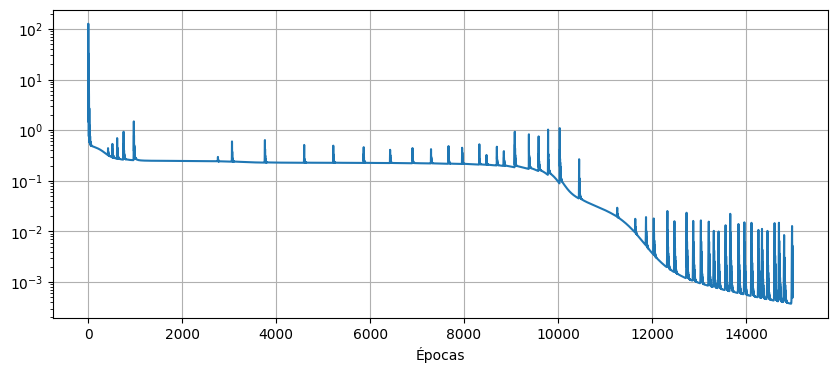

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize = (10, 4))
plt.plot(hist['loss'])
plt.xlabel('Épocas')
plt.grid()
plt.yscale('log')
plt.show()

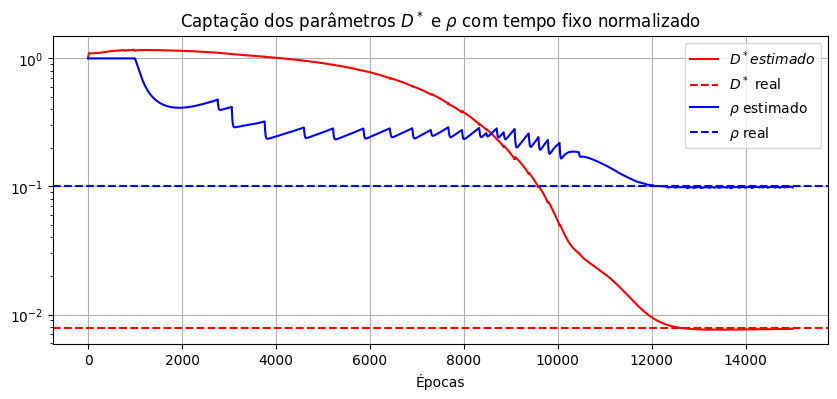

In [3]:
plt.figure(figsize = (10, 4))
plt.plot(hist['d'], label = r'$D^* estimado$', color = 'red')
plt.axhline(D_TRUE, label = r'$D^*$ real', color = 'red', linestyle = '--')
plt.plot(hist['rho'], label = r'$\rho$ estimado', color = 'blue')
plt.axhline(RHO_TRUE, label = r'$\rho$ real', color = 'blue', linestyle = '--')
plt.title(r'Captação dos parâmetros $D^*$ e $\rho$ com tempo fixo normalizado')
plt.xlabel('Épocas')
plt.grid()
plt.yscale('log')
plt.legend()
plt.show()